# Design rainfall at Toronto Pearson

Inspect ECCC's published **15-minute, 1-hour and 24-hour rainfall intensities**
for climate ID **6158731** (Toronto Pearson) and check how well a Gumbel
distribution reproduces them. The headless twin is
[`pipelines/eccc_idf_pipeline.py`](../../pipelines/eccc_idf_pipeline.py).

crc-sdk reads ECCC's current IDF release (3.40) for one province. For each
duration, a station's published central rates are a quantile curve with one
knot per published return period (2 to 200 years), used exactly as published.
The pipeline also fits a Gumbel distribution to those knots and reports the
residual at each knot, next to ECCC's published 95% confidence half-width.

These are historical station estimates: no climate adjustment and no spatial
interpolation to nearby properties. The first run downloads Ontario's provincial
bundle (about 150 MB); later runs reuse the cache.

Run from a crc-docs checkout: `uv sync --locked`, then `uv run jupyter lab`.

In [1]:
#@title Install dependencies and prepare this notebook
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--pre",
                           "--disable-pip-version-check", "crc-sdk>=1.0.0a2,<2", "plotly>=6"])
ROOT = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines/eccc_idf_pipeline.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow.parquet as pq
from IPython.display import display
from plotly.subplots import make_subplots

from pipelines.eccc_idf_pipeline import run

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"

## Select stations and durations

Use explicit climate IDs when you know the station. For a region, set `AREAS`
to one or more WGS84 boxes inside the province; their union is selected and a
station in two boxes is counted once. `MODE = "offline"` replays the cached
bytes without network access after one online run.

In [2]:
PROVINCE = "ON"
STATIONS = ["6158731"]
AREAS = None  # e.g. [(-79.65, 43.65, -79.61, 43.70), (-75.70, 45.30, -75.65, 45.35)]
DURATIONS = ["15min", "1h", "24h"]
MODE = "reuse"
OUTPUT = Path("pipeline_output/eccc_idf")

summary = run(OUTPUT, province=PROVINCE, stations=None if AREAS else STATIONS, areas=AREAS,
              durations=DURATIONS, cache_mode=MODE)
rates = pq.read_table(OUTPUT / "rainfall_rates.parquet").to_pandas()
print(f"ECCC IDF release {summary['release']}: {summary['rate_rows']} rates for stations "
      f"{', '.join(summary['stations'])}; largest refit residual "
      f"{summary['maximum_absolute_fit_residual_mm_h']:.3f} mm/h")
display(rates.drop_duplicates("station")[["station", "name", "latitude", "longitude", "start_year", "end_year"]])

ECCC IDF release 3.40: 21 rates for stations 6158731; largest refit residual 0.050 mm/h


,station,name,latitude,longitude,start_year,end_year
0,6158731,TORONTO INTL A,43.666667,-79.633333,1950,2017


## Published rates and the Gumbel refit

Markers are ECCC's central estimates with their **published 95% confidence
half-widths**; lines are the Gumbel refit, queried at the same return periods
(`q = 1 − 1/T`). The error bars describe uncertainty in ECCC's estimates, not
errors in the refit or the chance of a particular storm.

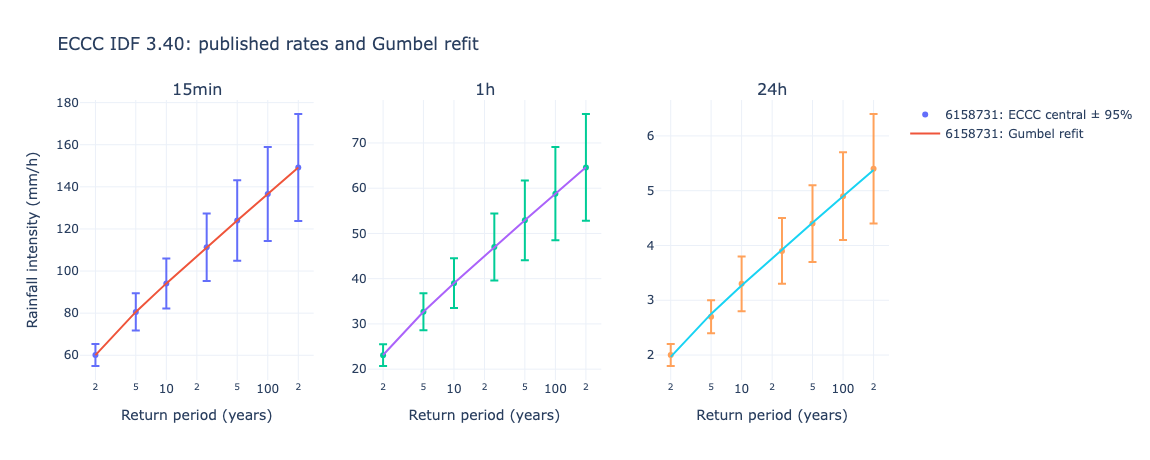

,station,duration,return_period_years,published_mm_h,confidence_95_half_width_mm_h,fitted_mm_h,fit_residual_mm_h
0,6158731,15min,2.0,60.1,5.2,60.095,-0.005
1,6158731,15min,5.0,80.6,8.8,80.581,-0.019
2,6158731,15min,10.0,94.1,11.9,94.144,0.044
3,6158731,15min,25.0,111.3,16.0,111.282,-0.018
4,6158731,15min,50.0,124.0,19.1,123.995,-0.005
5,6158731,15min,100.0,136.6,22.3,136.615,0.015
6,6158731,15min,200.0,149.2,25.4,149.189,-0.011
7,6158731,1h,2.0,23.1,2.4,23.133,0.033
8,6158731,1h,5.0,32.7,4.1,32.676,-0.024
9,6158731,1h,10.0,39.0,5.5,38.995,-0.005


In [3]:
fig = make_subplots(rows=1, cols=len(DURATIONS), subplot_titles=DURATIONS)
for col, duration in enumerate(DURATIONS, 1):
    for station, view in rates[rates.duration == duration].groupby("station"):
        fig.add_trace(go.Scatter(
            x=view.return_period_years, y=view.published_mm_h, mode="markers",
            error_y=dict(type="data", array=view.confidence_95_half_width_mm_h),
            name=f"{station}: ECCC central ± 95%", showlegend=col == 1), row=1, col=col)
        fig.add_trace(go.Scatter(
            x=view.return_period_years, y=view.fitted_mm_h, mode="lines",
            name=f"{station}: Gumbel refit", showlegend=col == 1), row=1, col=col)
fig.update_xaxes(title_text="Return period (years)", type="log")
fig.update_yaxes(title_text="Rainfall intensity (mm/h)", col=1)
fig.update_layout(title=f"ECCC IDF {summary['release']}: published rates and Gumbel refit",
                  height=460, width=1150)
fig.show()
display(rates[["station", "duration", "return_period_years", "published_mm_h",
               "confidence_95_half_width_mm_h", "fitted_mm_h", "fit_residual_mm_h"]].round(3))

## Rainfall depths over each duration

For screening, an intensity times its duration in hours gives the rainfall
amount over that interval. It is **not flood depth at a property**. Rates are
rounded to 0.1 mm/h, so converted amounts can differ slightly from ECCC's own
amount table. `beyond_record_span` flags return periods longer than the
station's record; those are extrapolations. A 24-hour moving maximum is not a
calendar-day Rx1day.

In [4]:
display(rates[rates.return_period_years.isin([10, 100])][[
    "station", "duration", "return_period_years", "published_mm_h",
    "published_duration_depth_mm", "start_year", "end_year", "beyond_record_span",
]])

,station,duration,return_period_years,published_mm_h,published_duration_depth_mm,start_year,end_year,beyond_record_span
2,6158731,15min,10.0,94.1,23.525,1950,2017,False
5,6158731,15min,100.0,136.6,34.150,1950,2017,True
9,6158731,1h,10.0,39.0,39.000,1950,2017,False
12,6158731,1h,100.0,58.8,58.800,1950,2017,True
16,6158731,24h,10.0,3.3,79.200,1950,2017,False
19,6158731,24h,100.0,4.9,117.600,1950,2017,True


## Run it headlessly

```sh
uv run python pipelines/eccc_idf_pipeline.py
uv run python pipelines/eccc_idf_pipeline.py --cache-mode offline
uv run python pipelines/eccc_idf_pipeline.py --province ON \
  --bounds -79.65 43.65 -79.61 43.70 --bounds -75.70 45.30 -75.65 45.35
```

Outputs: `rainfall_rates.parquet` (published rates, half-widths, refit and
residuals) and `summary.json`. Only ECCC's current release is published through
crc-sdk, so comparing releases (for example 3.20 with 3.40) is not part of this
workflow any more.

Source: [ECCC Engineering Climate Datasets](https://climate.weather.gc.ca/prods_servs/engineering_e.html).
Contains information licensed under the
[Open Government Licence – Canada](https://open.canada.ca/en/open-government-licence-canada).